In [1]:
#Все необходимые библиотеки
import pandas as pd
import os
import numpy as np
import cv2
from PIL import Image
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch as th

import torchvision
from torchvision import datasets, models
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

from skimage.io import imread
from torch.utils import data
from tqdm import tqdm

import glob
import re

import time

from sklearn.metrics import confusion_matrix
import seaborn as sns

from torchmetrics.classification import MulticlassSpecificity
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import matthews_corrcoef

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Класс для создания общего датасета с метаданными
class CombineDataset(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, is_aug):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.is_aug = is_aug
        
        if self.is_aug == 1:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.RandomHorizontalFlip(),
                    transforms.RandomRotation(degrees=60),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        else:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
            
            

    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img_name = self.frame[self.id_col].iloc[idx]
        img = os.path.join (self.path_imgs, img_name +'.jpg')

        image1 = Image.open(img)
        image = self.aug(image1)

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return image, feats, label, name
    
class CombineDataset_cache(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, use_cache = False):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.inputs_dtype = torch.float32
        
        self.transform = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        
        self.use_cache = use_cache
        
        if self.use_cache:
            self.cached_data = []

            progressbar = tqdm(range(len(self.path_imgs)), desc='Caching')
            
            for i, img in zip(progressbar, self.path_imgs):
                img = Image.open(img)
                img= self.transform(img)                
                self.cached_data.append(img)
            
    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img = self.cached_data[idx]

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return img, feats, label, name
    
    
    # Определение процессора для обучения 
def get_default_device():
    if torch.cuda.is_available():
        
        return torch.device('cuda')
    else:
        return torch.device('cpu')

In [3]:
#Класс для выведения индексов для разделения базы изображений
class Sampler(object):
    def __init__(self, data_source):
        pass
    
    def __iter__(self):
        raise NotImplementedError
        
    def __len__(self):
        raise NotImplementedError
        
class StratifiedSampler(Sampler):
    
    def __init__(self, class_vector, z):
        self.n_splits = 1
        self.class_vector = class_vector
        self.test_size = z

    def gen_sample_array(self):
        try:
            from sklearn.model_selection import StratifiedShuffleSplit
        except:
             print('Ошибка распределения изображений')
        import numpy as np
        
        s = StratifiedShuffleSplit(n_splits=self.n_splits, test_size=self.test_size)
        X = th.randn(self.class_vector.size(0),2).numpy()
        y = self.class_vector.numpy()
        s.get_n_splits(X, y)

        train_index, test_index= next(s.split(X, y))
        return train_index, test_index

    def __iter__(self):
        return iter(self.gen_sample_array())

    def __len__(self):
        return len(self.class_vector)

In [4]:
data_dir = "C:\\Users\\Ulyana\\...\\CLEAN DATASET\\"
metadata = pd.read_csv('C:\\Users\\Ulyana\\...\\MetaData2.csv')

numbers = re.compile(r'(\d+)')
def numericalSort(value):
    parts = numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts

data_dir2 = sorted(glob.glob('C:\\Users\\Ulyana\\...\\CLEAN DATASET\\*.jpg'), key=numericalSort)

labels_cat = ['0. vascular lesions', '1. nevus', '2. solar lentigo', '3. dermatofibroma', '4. seborrheic ketarosis', '5. benign ketarosis', '6. actinic keratosis', '7. basal cell carcinoma', '8. squamous cell carcinoma', '9. melanoma']
labels_cat2 = ['vascular lesions', 'nevus', 'solar lentigo', 'dermatofibroma', 'seborrheic ketarosis', 'benign ketarosis', 'actinic keratosis', 'basal cell carcinoma', 'squamous cell carcinoma', 'melanoma']

img_size = 227
num_classes = 10
num_epochs = 10

#CPU или GPU
device = get_default_device()
device

device(type='cuda')

In [5]:
#Кодируем метаданные

metadata_age = metadata[['age']]
Age_grup = []

for i in metadata_age['age']:
    if i <= 44:
        Age_grup += ['young']
        #print('молодой')
    elif 45 <= i <= 59:
        Age_grup += ['middle']
        #print('средний')
    elif 60 <= i <= 74:
        Age_grup += ['elderly']
        #print('пожилой')
    elif 75 <= i:
        Age_grup += ['senile']
        #print('долгожители')
    else:
        Age_grup += ['error']
        #print('ошибка')
        
metadata['age'] = Age_grup

In [6]:
#Кодируем метаданные

encode_map_categor = {'0. vascular lesions': 0, '1. nevus': 1, '2. solar lentigo': 2, '3. dermatofibroma': 3, '4. seborrheic ketarosis': 4, '5. benign ketarosis': 5, '6. actinic keratosis': 6, '7. basal cell carcinoma': 7, '8. squamous cell carcinoma': 8, '9. melanoma': 9}

encode_map_age = {'young': 0, 'middle': 1, 'elderly': 2, 'senile': 3}
encode_map_sex = {'male': 0, 'female': 1}
encode_map_anatomloc = {'anterior torso': 0, 'head/neck': 1, 'lateral torso': 2, 'lower extremity': 3, 'oral/genital': 4, 'palms/soles': 5, 'posterior torso': 6, 'upper extremity': 7}

#encode_map_age = {'young': '0001', 'middle': '0010', 'elderly': '0100', 'senile': '1000'}
#encode_map_sex = {'male': '01', 'female': '10'}
#encode_map_anatomloc = {'anterior torso': '00000001', 'head/neck': '00000010', 'lateral torso': '00000100', 'lower extremity': '00001000', 'oral/genital': '00010000', 'palms/soles': '00100000', 'posterior torso': '01000000', 'upper extremity': '10000000'}

metadata['diagnosis'].replace(encode_map_categor, inplace=True)
metadata['age'].replace(encode_map_age, inplace=True)
metadata['sex'].replace(encode_map_sex, inplace=True)
metadata['anatomloc'].replace(encode_map_anatomloc, inplace=True)

metadata['diagnosis'] = np.array(metadata['diagnosis'], dtype=np.int32)
metadata['age'] = np.array(metadata['age'], dtype=np.int32)
metadata['sex'] = np.array(metadata['sex'], dtype=np.int32)
metadata['anatomloc'] = np.array(metadata['anatomloc'], dtype=np.int32)

C:\Users\Ulyana\AppData\Local\Temp\ipykernel_16712\1033980212.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  metadata['diagnosis'].replace(encode_map_categor, inplace=True)
C:\Users\Ulyana\AppData\Local\Temp\ipykernel_16712\1033980212.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  metada

In [32]:
#Определяем индексы для разделения базы изображений

test_size = 0.2
valid_size = 0.25

data_label = metadata['diagnosis'].to_numpy()

ss = StratifiedSampler(torch.FloatTensor(data_label), test_size)
pre_train_indices, test_indices = ss.gen_sample_array()

train_label = np.delete(data_label, test_indices, None)
ss = StratifiedSampler(torch.FloatTensor(train_label), valid_size)
train_indices, val_indices = ss.gen_sample_array()

indices = {'train': pre_train_indices[train_indices],
           'val': pre_train_indices[val_indices],
           'test': test_indices
           }

train_indices = indices['train']
val_indices = indices['val']
test_indices = indices['test']

#Выводим индексы для разделения базы изображений

print("Размер тренировочной базы:", len(train_indices))
print("Размер валидационной базы:", len(val_indices))
print("Размер тестовой базы:", len(test_indices))

#torch.save(train_indices, 'Parametr\\train_indices.pt')
#torch.save(val_indices, 'Parametr\\val_indices.pt')
#torch.save(test_indices, 'Parametr\\test_indices.pt')

#train_indices = torch.load('Parametr\\train_indices.pt', weights_only=False)
#val_indices = torch.load('Parametr\\val_indices.pt', weights_only=False)
#test_indices = torch.load('Parametr\\test_indices.pt', weights_only=False)

Размер тренировочной базы: 25035
Размер валидационной базы: 8345
Размер тестовой базы: 8345


In [8]:
len_valset = len(val_indices)
len_trainset = len(train_indices)

In [9]:
#Функция для получения веса для каждой категории
def estimate_weights_mfb(label):
    class_weights = np.zeros_like(label, dtype=float)
    counts = np.zeros_like(label)
    for i,l in enumerate(label):
        m = metadata['diagnosis'].value_counts()
        counts[i] = m[i]
    counts = counts.astype(float)
    median_freq = np.median(counts)
    
    for i, label in enumerate(label):
        class_weights[i] = median_freq / counts[i]
    return class_weights

weight = estimate_weights_mfb(labels_cat)
weight = torch.FloatTensor(weight).to(device)

for i in range(len(labels_cat)):
    print(labels_cat[i],":", weight[i])

0. vascular lesions : tensor(3.8893, device='cuda:0')
1. nevus : tensor(0.0353, device='cuda:0')
2. solar lentigo : tensor(3.6444, device='cuda:0')
3. dermatofibroma : tensor(4., device='cuda:0')
4. seborrheic ketarosis : tensor(0.6721, device='cuda:0')
5. benign ketarosis : tensor(0.8954, device='cuda:0')
6. actinic keratosis : tensor(1.1323, device='cuda:0')
7. basal cell carcinoma : tensor(0.2900, device='cuda:0')
8. squamous cell carcinoma : tensor(1.5000, device='cuda:0')
9. melanoma : tensor(0.1758, device='cuda:0')


In [10]:
Data_set = CombineDataset_cache(metadata, 'name', 'diagnosis', data_dir2, use_cache = True)

batch_size = 16

trainloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = train_indices)
valloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = val_indices)
testloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = test_indices)

Caching: 100%|██████████████████████████████████████████████████████████████████| 41725/41725 [01:52<00:00, 372.08it/s]


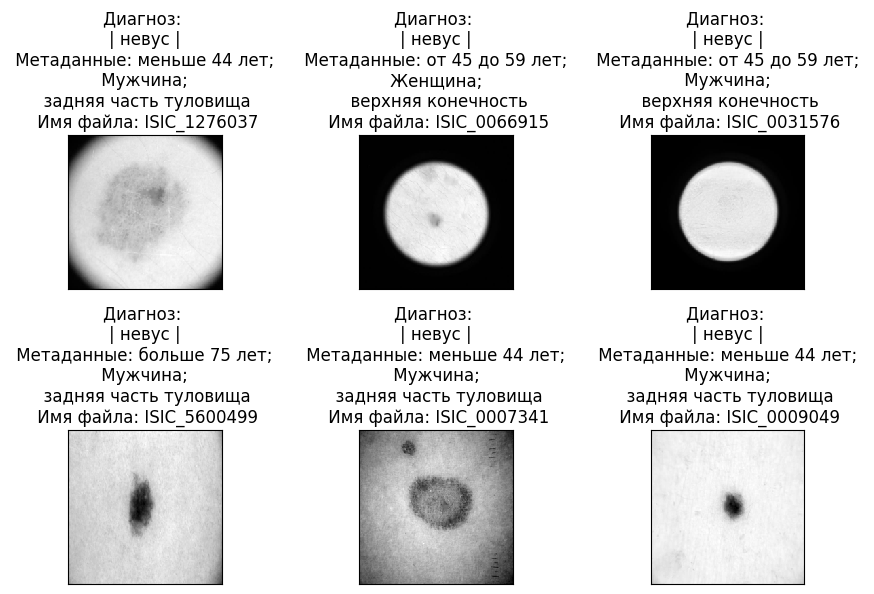

In [12]:
age = ['меньше 44 лет', 'от 45 до 59 лет', 'от 60 до 74 лет', 'больше 75 лет']
sex = ['Мужчина', 'Женщина']
anatomloc = ['торс', 'голова/шея', 'боковая часть туловища', 'нижняя конечность', 'оральная/генитальная зона', 'ладони/подошвы', 'задняя часть туловища', 'верхняя конечность']
lab = ['сосудистое поражение', 'невус', 'солнечное лентиго', 'дерматофиброма', 'себорейный кератоз', 'доброкачественный кератоз', 'актинический кератоз', 'базально-клеточная карцинома', 'плоскоклеточный рак', 'меланома']


examples = enumerate(trainloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

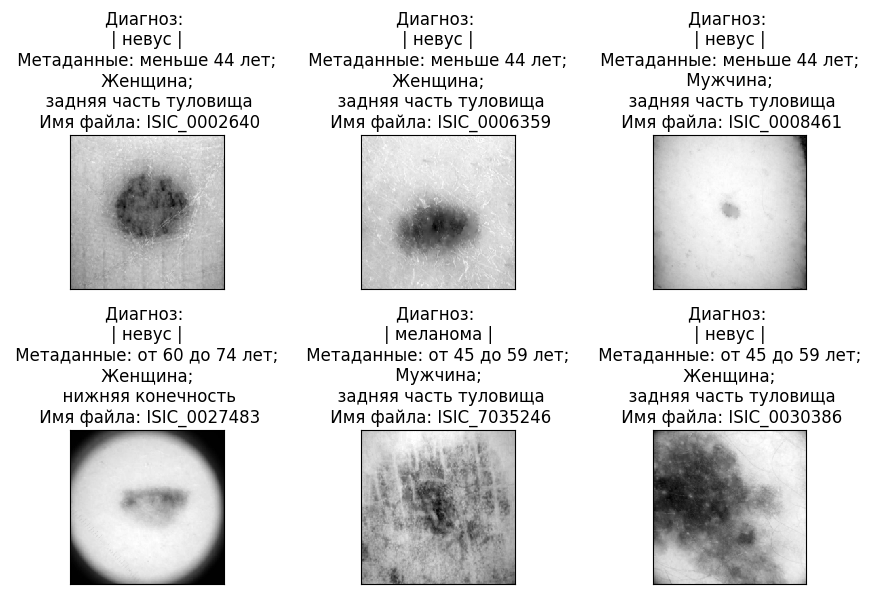

In [13]:
examples = enumerate(valloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

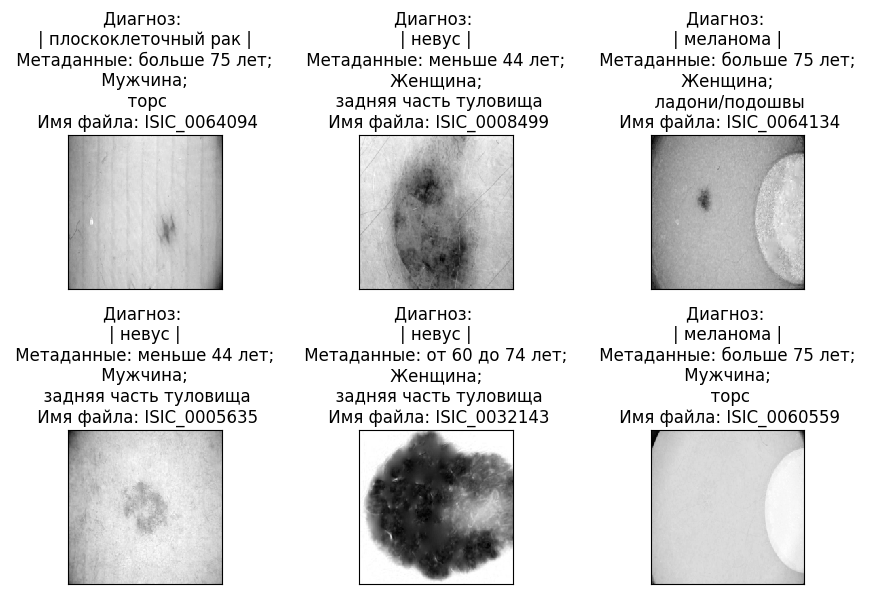

In [14]:
examples = enumerate(testloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

In [15]:
from torchvision.models import densenet201, DenseNet201_Weights

densenet201 = models.densenet201(weights = DenseNet201_Weights.IMAGENET1K_V1)
densenet201.classifier = nn.Linear(2208, num_classes)

class Classification_M(nn.Module):
    def __init__(self):
        super(Classification_M, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_M = Classification_M()    
    
class MultimodalNN(nn.Module):
    def __init__(self):
        super(MultimodalNN, self).__init__()
        
        self.CNN = densenet201
       
        self.meta_net = Classification_M
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

NET_deep = MultimodalNN()

model_name = 'densenet201.pt'
model_weights = torch.load(model_name, device)
NET_deep.load_state_dict(model_weights)
NET_deep = NET_deep.to(device)

NET_deep

MultimodalNN(
  (CNN): DenseNet(
    (features): Sequential(
      (conv0): Conv2d(3, 96, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (norm0): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu0): ReLU(inplace=True)
      (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (denseblock1): _DenseBlock(
        (denselayer1): _DenseLayer(
          (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu1): ReLU(inplace=True)
          (conv1): Conv2d(96, 192, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (norm2): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu2): ReLU(inplace=True)
          (conv2): Conv2d(192, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        )
        (denselayer2): _DenseLayer(
          (norm1): BatchNorm2d(144, eps=1e-05, momentum=0

In [16]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
nn_light = MultimodalNN_light().to(device)

torch.manual_seed(42)
new_nn_light = MultimodalNN_light().to(device)

#model_name = 'Parametr\\nn_light_2.pt'
#torch.save(nn_light.state_dict(), model_name)

nn_light

MultimodalNN_light(
  (CNN): Net(
    (layer1): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=128, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=10, bias=True)
  )
  (meta_net): Classification_MM(
    (layer_1): Linear(in_features=3, out_features=64, bias=True)
    (relu1): ReLU()
  

In [17]:
#print("Норма 1-го слоя в nn_deep:", torch.norm(nn_deep.features[0].weight).item())
#print("Норма 1-го слоя в  nn_light:", torch.norm(nn_light.features[0].weight).item())
#print("Норма 1-го слоя в  new_nn_light:", torch.norm(new_nn_light.features[0].weight).item())

In [18]:
total_params_deep = "{:,}".format(sum(p.numel() for p in NET_deep.parameters()))
print(f"nn_deep параметры: {total_params_deep}")
total_params_light = "{:,}".format(sum(p.numel() for p in nn_light.parameters()))
print(f"nn_light параметры: {total_params_light}")
total_params_light = "{:,}".format(sum(p.numel() for p in new_nn_light.parameters()))
print(f"new_nn_light параметры: {total_params_light}")

nn_deep параметры: 26,497,158
nn_light параметры: 267,686
new_nn_light параметры: 267,686


In [19]:
def test(model, dataset, device):

    start_time_glob = time.time()
    model.to(device)
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for i, data in enumerate(dataset):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)

            outputs = model(inputs, feats)
            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    
    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
    
    return accuracy

def test_NN(model, dataset):

    start_time_glob = time.time()
    model.eval()
    
    with torch.no_grad():
        for data in dataset:
            image, feats, label, name = data
            image, feats, label = image.to(device), feats.to(device), label.to(device)

            output = model(image, feats)

            pred = (torch.max(torch.exp(output), 1)[1]).cpu().data.numpy()

            predictions.extend(pred)

            label = label.cpu().data.numpy()
            actuals.extend(label)

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
        
def test_metric():
    
    cm = confusion_matrix(actuals, predictions)
    FP = np.mean(cm.sum(axis=0) - np.diag(cm))  
    FN = np.mean(cm.sum(axis=1) - np.diag(cm))
    TP = np.mean(np.diag(cm))
    TN = np.mean(cm.sum() - (FP + FN + TP))

    Sensitivity = (TP/(TP+FN))
    Specificity = (TN/(TN+FP))
    Precision = (TP/(TP+FP))
    NPV = (TN/(TN+FN))
    PPV = (TP/(TP+FP))
    FNR = (FN/(FN+TP))
    FPR = (FP/(FP+TN))

    F1 = (2*TP)/((2*TP)+FP+FN)

    print('Sensitivity: %.4f' % Sensitivity)
    print('Specificity: %.4f' % Specificity)
    print('Precision: %.4f' % Precision)
    print('NPV: %.4f' % NPV)
    print('PPV: %.4f' % PPV)
    print('FNR: %.4f' % FNR)
    print('FPR: %.4f' % FPR)
    print('F1: %.4f' % F1)


    recall_1 = recall_score(actuals, predictions, average='micro')
    print('Recall micro: %.4f' % recall_1)
    recall_2 = recall_score(actuals, predictions, average='macro')
    print('Recall macro: %.4f' % recall_2)

    precision_1 = precision_score(actuals, predictions, average='micro')
    print('Precision micro: %.4f' % precision_1)
    precision_2 = precision_score(actuals, predictions, average='macro')
    print('Precision macro: %.4f' % precision_2)


    f1_1 = f1_score(actuals, predictions, average='micro')
    print('F1 score micro: %.4f' % f1_1)
    f1_2 = f1_score(actuals, predictions, average='macro')
    print('F1 score macro: %.4f' % f1_2)
    
    jaccard_1 = jaccard_score(actuals, predictions, average='micro')
    print('Jaccard score micro: %.4f' % jaccard_1)
    jaccard_2 = jaccard_score(actuals, predictions, average='macro')
    print('Jaccard score macro: %.4f' % jaccard_2)

    accuracy_1 = accuracy_score(actuals, predictions)
    print('Accuracy score: %.4f' % accuracy_1)

    MCC = matthews_corrcoef(actuals, predictions)
    print('Matthews corrcoef: %.4f' % MCC)

    pre = torch.tensor(predictions)
    ac = torch.tensor(actuals)

    specificity1 = MulticlassSpecificity(average='macro', num_classes=10)
    s1 = specificity1(pre, ac)
    print('Specificity macro: %.4f' % s1)

    specificity2 = MulticlassSpecificity(average='micro', num_classes=10)
    s2 = specificity2(pre, ac)
    print('Specificity micro: %.4f' % s2)

    specificity3 = MulticlassSpecificity(average='weighted', num_classes=10)
    s3 = specificity3(pre, ac)
    print('Specificity weighted: %.4f' % s3)

    specificity4 = MulticlassSpecificity(average='none', num_classes=10)
    s4 = specificity4(pre, ac)
    print('Specificity none - class vascular lesions (0): %.4f' % s4[0])
    print('Specificity none - class nevus (1): %.4f' % s4[1])
    print('Specificity none - class solar lentigo (2): %.4f' % s4[2])
    print('Specificity none - class dermatofibroma (3): %.4f' % s4[3])
    print('Specificity none - class seborrheic ketarosis (4): %.4f' % s4[4])
    print('Specificity none - class benign ketarosis (5): %.4f' % s4[5])
    print('Specificity none - class actinic keratosis (6): %.4f' % s4[6])
    print('Specificity none - class basal cell carcinoma (7): %.4f' % s4[7])
    print('Specificity none - class squamous cell carcinoma (8): %.4f' % s4[8])
    print('Specificity none - class melanoma (9): %.4f' % s4[9])

____________________________________________________________
Время тестирования: 00:00:16
Время тестирования в секундах: 16.976168



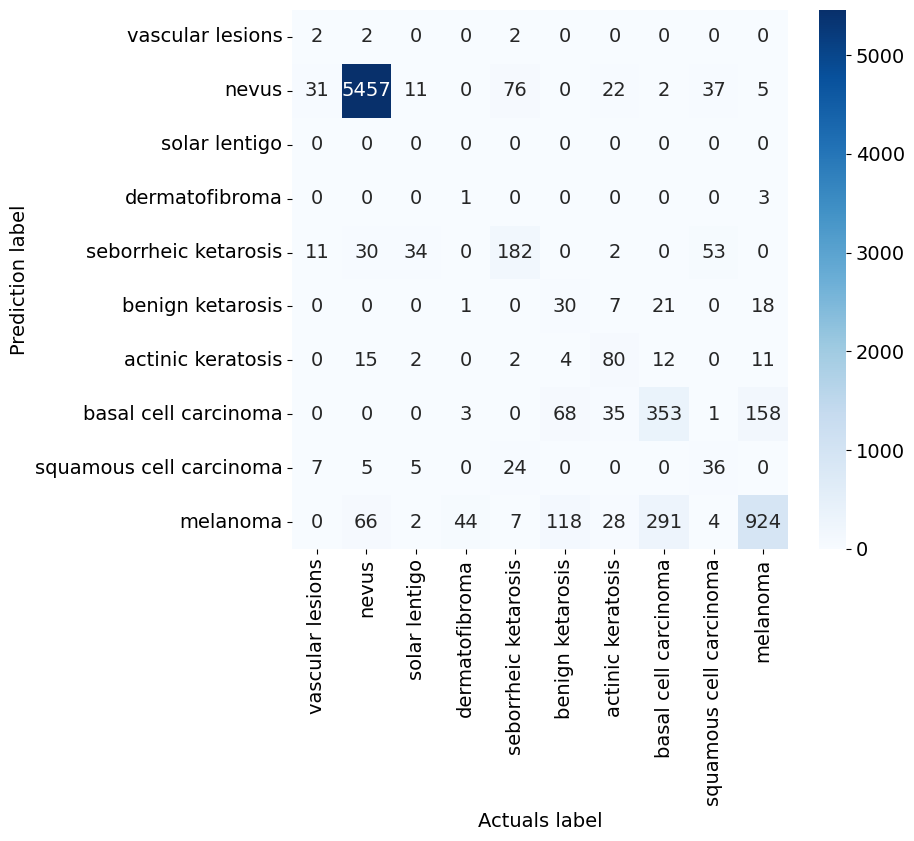

Sensitivity: 0.8466
Specificity: 0.9830
Precision: 0.8466
NPV: 0.9830
PPV: 0.8466
FNR: 0.1534
FPR: 0.0170
F1: 0.8466
Recall micro: 0.8466
Recall macro: 0.3876
Precision micro: 0.8466
Precision macro: 0.4820
F1 score micro: 0.8466
F1 score macro: 0.4018
Jaccard score micro: 0.7340
Jaccard score macro: 0.3043
Accuracy score: 0.8466
Matthews corrcoef: 0.7049
Specificity macro: 0.9788
Specificity micro: 0.9830
Specificity weighted: 0.9415
Specificity none - class vascular lesions (0): 0.9995
Specificity none - class nevus (1): 0.9336
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 0.9996
Specificity none - class seborrheic ketarosis (4): 0.9839
Specificity none - class benign ketarosis (5): 0.9942
Specificity none - class actinic keratosis (6): 0.9944
Specificity none - class basal cell carcinoma (7): 0.9654
Specificity none - class squamous cell carcinoma (8): 0.9950
Specificity none - class melanoma (9): 0.9225


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [21]:
actuals = []
predictions = []

test_NN(NET_deep, testloader)

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.995263



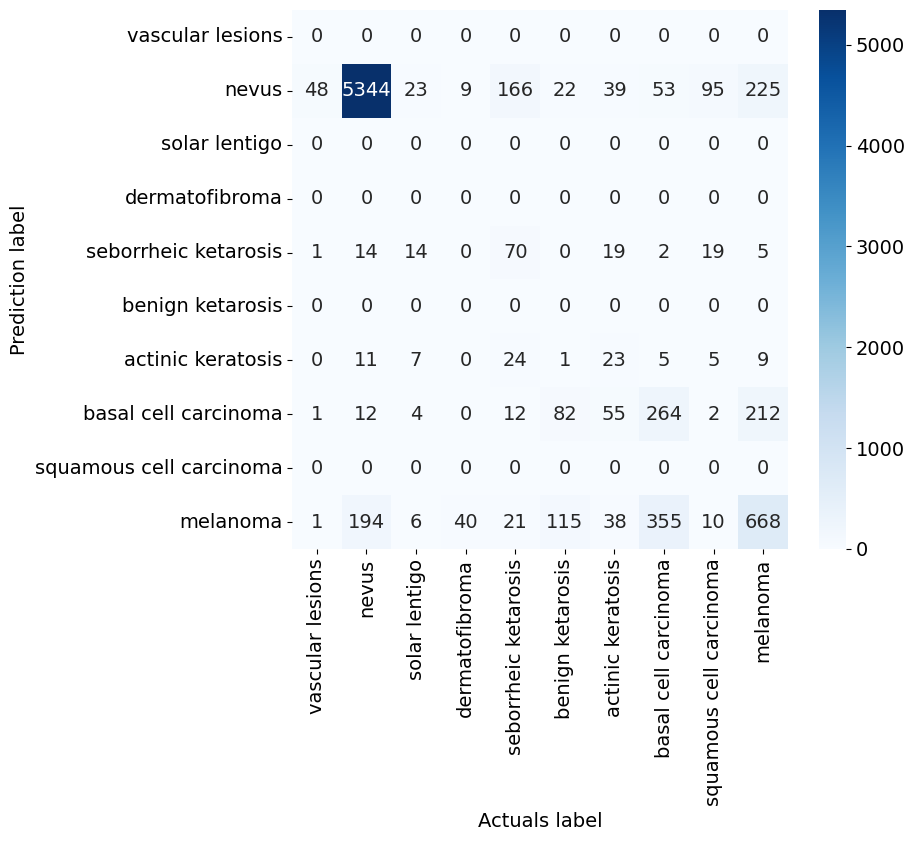

Sensitivity: 0.7632
Specificity: 0.9737
Precision: 0.7632
NPV: 0.9737
PPV: 0.7632
FNR: 0.2368
FPR: 0.0263
F1: 0.7632
Recall micro: 0.7632
Recall macro: 0.2315
Precision micro: 0.7632
Precision macro: 0.2515
F1 score micro: 0.7632
F1 score macro: 0.2339
Jaccard score micro: 0.6171
Jaccard score macro: 0.1744
Accuracy score: 0.7632
Matthews corrcoef: 0.5193
Specificity macro: 0.9580
Specificity micro: 0.9737
Specificity weighted: 0.8170
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7545
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9908
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9924
Specificity none - class basal cell carcinoma (7): 0.9504
Specificity none - class squamous cell carcinoma (8): 1.0000
Specificity none - class melanoma (9): 0.8921


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [23]:
actuals = []
predictions = []

test_NN(NET_light, testloader)

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

test_metric()

In [24]:
def loss_kd(outputs, labels, teacher_outputs, temparature, alpha):
    
    KD_loss = nn.KLDivLoss(reduction='batchmean')(F.log_softmax(outputs/temparature, dim=1), F.softmax(teacher_outputs/temparature,dim=1)) * (alpha * temparature * temparature) + F.cross_entropy(outputs, labels) * (1. - alpha)
    
    return KD_loss

def get_outputs(model, dataloader):
    outputs = []
    
    for inputs, feats, labels, name in dataloader:
        inputs_batch, feats_batch, labels_batch = inputs.cuda(), feats.cuda(), labels.cuda()
        output_batch = model(inputs_batch, feats_batch).data.cpu().numpy()
        outputs.append(output_batch)
       
    return outputs

In [25]:
import torch.nn.functional as F

def train_kd(model, teacher_out, optimizer, loss_kd, dataloader, temparature, alpha):
    
    model.train()
    start_time_tarin = time.time()
    
    running_loss = 0.0
    running_corrects = 0
    
    for i, data in enumerate(dataloader):
        inputs, feats, labels, name = data
        inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(inputs, feats)
        outputs_teacher = torch.from_numpy(teacher_out[i]).to(device)
        
        loss = loss_kd(outputs, labels, outputs_teacher, temparature, alpha)
        _, preds = torch.max(outputs, 1)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
   
    epoch_loss = running_loss / len_trainset
    epoch_acc = running_corrects.double() / len_trainset
    time_tarin = time.time()-start_time_tarin
    
    print('   Тренировочная ошибка: {:.4f} Точность: {:.4f}'.format(epoch_loss, epoch_acc))
    print ('        Время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_tarin))))
    
def eval_kd(model,teacher_out, optimizer, loss_kd, dataloader, temparature, alpha):
    
    model.eval()
    start_time_test = time.time()
    
    running_loss = 0.0
    running_corrects = 0
    
    for i, data in enumerate(dataloader):
        inputs, feats, labels, name = data
        inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
        
        outputs = model(inputs, feats)
        outputs_teacher = torch.from_numpy(teacher_out[i]).cuda()
        
        loss = loss_kd(outputs,labels,outputs_teacher,temparature, alpha)
        _, preds = torch.max(outputs, 1)
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
        
    epoch_loss = running_loss / len_valset
    epoch_acc = running_corrects.double() / len_valset

    time_test = time.time()-start_time_test
    
    print('   Валидационная ошибка: {:.4f} Точность: {:.4f}'.format(epoch_loss, epoch_acc))
    print ('        Время тестирования: {}\n'.format(time.strftime("%H:%M:%S", time.gmtime(time_test))))
    
    return epoch_acc


def train_and_evaluate_kd(model, teacher_model, optimizer, loss_kd, trainloader, valloader, temparature, alpha, num_epochs=20):

    teacher_model.eval()
    start_time_glob = time.time()
    start_time_teacher_model = time.time()
    
    print('Процесс вывода весов с архитектуры-учителя...')
    
    best_model_wts = copy.deepcopy(model.state_dict())
    outputs_teacher_train = get_outputs(teacher_model, trainloader)
    outputs_teacher_val = get_outputs(teacher_model, valloader)

    time_teacher_model = time.time()-start_time_teacher_model
    print ('Время вывода весов с архитектуры-учителя: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_teacher_model))))
    
    best_acc = 0.0
    
    for epoch in range(num_epochs):

        print('_' * 60)
        print('Эпоха {}/{}'.format(epoch+1, num_epochs))
        
        train_kd(model, outputs_teacher_train, optimizer, loss_kd, trainloader, temparature, alpha)
        epoch_acc_val = eval_kd(model, outputs_teacher_val, optimizer, loss_kd, valloader, temparature, alpha)

        torch.save(model.state_dict(), f"student_epoch-{epoch+1}.pth")
        
        if epoch_acc_val > best_acc:
            best_acc = epoch_acc_val
            best_model_wts = copy.deepcopy(model.state_dict())
            
            torch.save(model.state_dict(), f"BestModel_student.pth")
            
        model.load_state_dict(best_model_wts)
            
        print('Лучшая валидационная точность: {:.4f}'.format(best_acc))
        
    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('\nОбщее время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    
    return model

In [26]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.1, patience = 3)
optimizer = torch.optim.SGD(new_nn_light.parameters(), lr=0.001, momentum=0.9)

STUD_Model_1 = train_and_evaluate_kd (new_nn_light, NET_deep, optimizer, loss_kd, trainloader, valloader, 1, 0.5, 20)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:01:09
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 0.5440 Точность: 0.7644
        Время обучения: 00:01:10
   Валидационная ошибка: 0.4551 Точность: 0.7917
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7917
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 0.4476 Точность: 0.7864
        Время обучения: 00:01:10
   Валидационная ошибка: 0.4070 Точность: 0.8044
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.8044
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 0.4215 Точность: 0.7912
        Время обучения: 00:01:10
   Валидационная ошибка: 0.4088 Точность: 0.7978
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.8044
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.687641



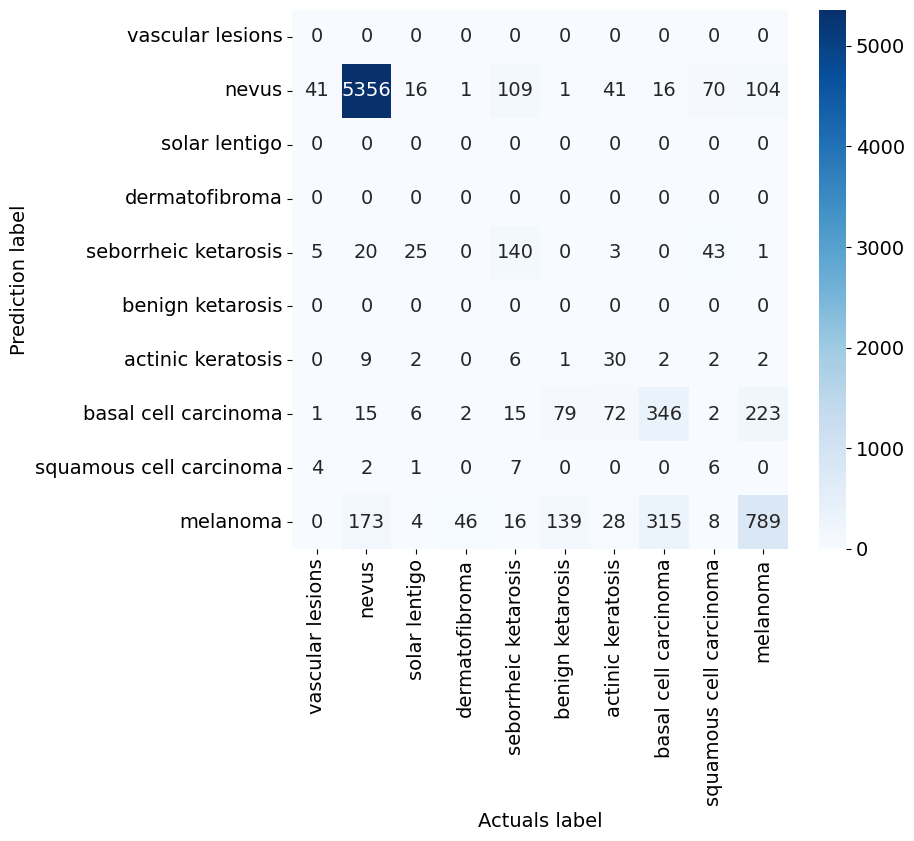

Sensitivity: 0.7989
Specificity: 0.9777
Precision: 0.7989
NPV: 0.9777
PPV: 0.7989
FNR: 0.2011
FPR: 0.0223
F1: 0.7989
Recall micro: 0.7989
Recall macro: 0.2871
Precision micro: 0.7989
Precision macro: 0.3351
F1 score micro: 0.7989
F1 score macro: 0.2895
Jaccard score micro: 0.6652
Jaccard score macro: 0.2192
Accuracy score: 0.7989
Matthews corrcoef: 0.6059
Specificity macro: 0.9684
Specificity micro: 0.9777
Specificity weighted: 0.8853
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8560
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9880
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9971
Specificity none - class basal cell carcinoma (7): 0.9459
Specificity none - class squamous cell carcinoma (8): 0.9983
Specificity none - class melanoma (9): 0.8991


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [29]:
actuals = []
predictions = []

test_NN(STUD_Model_1, testloader)

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

test_metric()

In [30]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_2 = MultimodalNN_light().to(device)

In [34]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.1, patience = 3)
optimizer = torch.optim.SGD(new_nn_light.parameters(), lr=0.001, momentum=0.9)

STUD_Model_2 = train_and_evaluate_kd (new_nn_light_2, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.5, 20)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:01:09
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 0.7298 Точность: 0.7927
        Время обучения: 00:01:09
   Валидационная ошибка: 0.7071 Точность: 0.8041
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.8041
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 0.7178 Точность: 0.7942
        Время обучения: 00:01:09
   Валидационная ошибка: 0.6813 Точность: 0.8059
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.8059
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 0.6985 Точность: 0.7973
        Время обучения: 00:01:09
   Валидационная ошибка: 0.6574 Точность: 0.8061
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.8061
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.375558



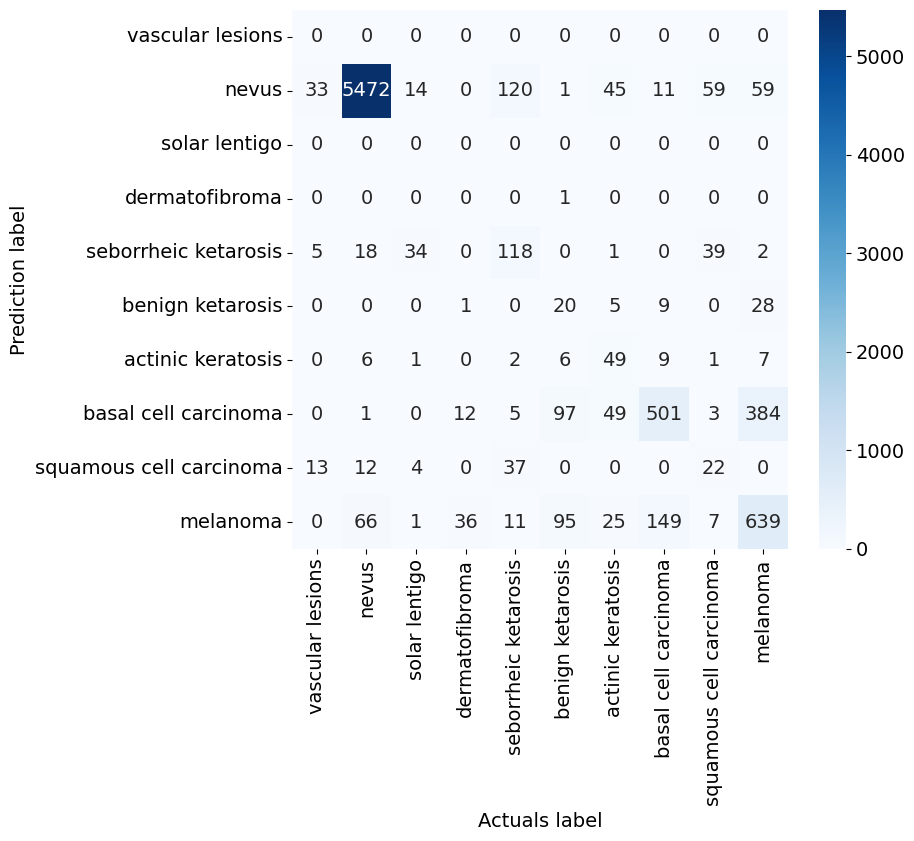

Sensitivity: 0.8174
Specificity: 0.9797
Precision: 0.8174
NPV: 0.9797
PPV: 0.8174
FNR: 0.1826
FPR: 0.0203
F1: 0.8174
Recall micro: 0.8174
Recall macro: 0.3234
Precision micro: 0.8174
Precision macro: 0.3755
F1 score micro: 0.8174
F1 score macro: 0.3324
Jaccard score micro: 0.6912
Jaccard score macro: 0.2482
Accuracy score: 0.8174
Matthews corrcoef: 0.6422
Specificity macro: 0.9721
Specificity micro: 0.9797
Specificity weighted: 0.9037
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8765
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 0.9999
Specificity none - class seborrheic ketarosis (4): 0.9877
Specificity none - class benign ketarosis (5): 0.9947
Specificity none - class actinic keratosis (6): 0.9961
Specificity none - class basal cell carcinoma (7): 0.9281
Specificity none - class squamous cell carcinoma (8): 0.9920
Specificity none - class melanoma (9): 0.9460


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [37]:
actuals = []
predictions = []

test_NN(STUD_Model_2, testloader)

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

test_metric()

In [38]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_3 = MultimodalNN_light().to(device)

In [39]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.1, patience = 3)
optimizer = torch.optim.SGD(new_nn_light.parameters(), lr=0.001, momentum=0.9)

STUD_Model_3 = train_and_evaluate_kd (new_nn_light_3, NET_deep, optimizer, loss_kd, trainloader, valloader, 5, 0.5, 15)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:01:09
____________________________________________________________
Эпоха 1/15
   Тренировочная ошибка: 3.0748 Точность: 0.7307
        Время обучения: 00:01:10
   Валидационная ошибка: 2.1818 Точность: 0.7668
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7668
____________________________________________________________
Эпоха 2/15
   Тренировочная ошибка: 2.0983 Точность: 0.7782
        Время обучения: 00:01:10
   Валидационная ошибка: 1.8881 Точность: 0.7872
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7872
____________________________________________________________
Эпоха 3/15
   Тренировочная ошибка: 1.9214 Точность: 0.7859
        Время обучения: 00:01:10
   Валидационная ошибка: 1.7596 Точность: 0.7946
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7946
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.113300



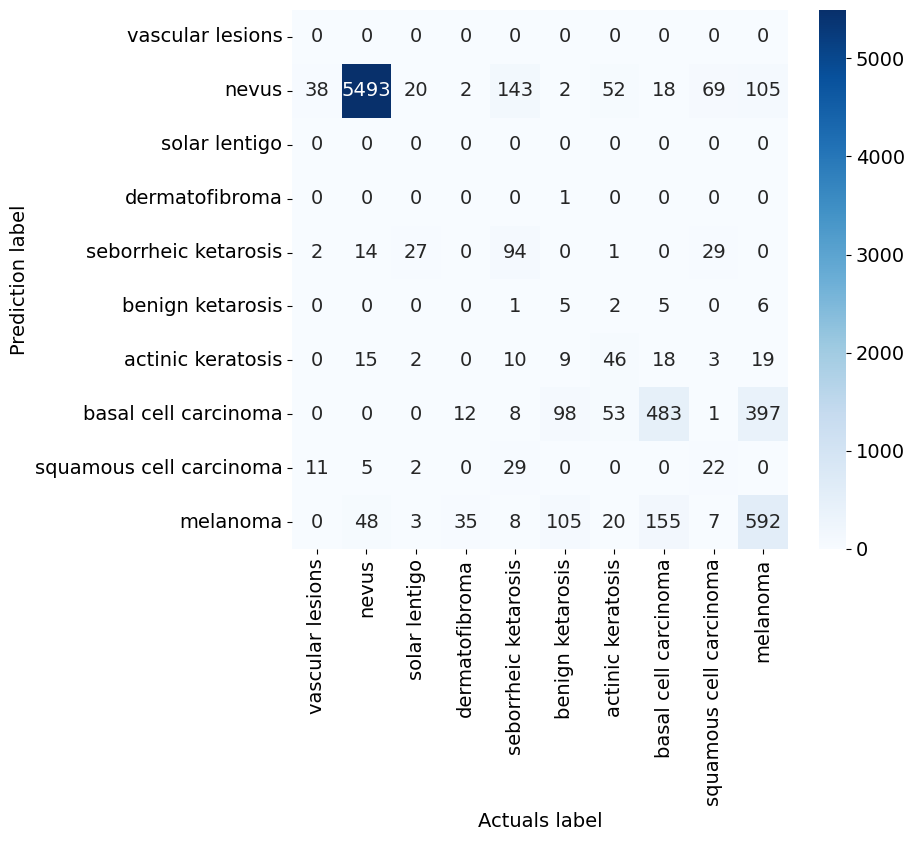

Sensitivity: 0.8071
Specificity: 0.9786
Precision: 0.8071
NPV: 0.9786
PPV: 0.8071
FNR: 0.1929
FPR: 0.0214
F1: 0.8071
Recall micro: 0.8071
Recall macro: 0.3002
Precision micro: 0.8071
Precision macro: 0.3514
F1 score micro: 0.8071
F1 score macro: 0.3059
Jaccard score micro: 0.6765
Jaccard score macro: 0.2279
Accuracy score: 0.8071
Matthews corrcoef: 0.6165
Specificity macro: 0.9685
Specificity micro: 0.9786
Specificity weighted: 0.8780
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8379
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 0.9999
Specificity none - class seborrheic ketarosis (4): 0.9909
Specificity none - class benign ketarosis (5): 0.9983
Specificity none - class actinic keratosis (6): 0.9907
Specificity none - class basal cell carcinoma (7): 0.9258
Specificity none - class squamous cell carcinoma (8): 0.9943
Specificity none - class melanoma (9): 0.9473


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [41]:
actuals = []
predictions = []

test_NN(STUD_Model_3, testloader)

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

test_metric()

In [42]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_4 = MultimodalNN_light().to(device)

In [43]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.1, patience = 3)
optimizer = torch.optim.SGD(new_nn_light.parameters(), lr=0.001, momentum=0.9)

STUD_Model_4 = train_and_evaluate_kd (new_nn_light_4, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.25, 10)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:01:09
____________________________________________________________
Эпоха 1/10
   Тренировочная ошибка: 1.0409 Точность: 0.7345
        Время обучения: 00:01:09
   Валидационная ошибка: 0.7609 Точность: 0.7747
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7747
____________________________________________________________
Эпоха 2/10
   Тренировочная ошибка: 0.7387 Точность: 0.7830
        Время обучения: 00:01:09
   Валидационная ошибка: 0.6872 Точность: 0.7890
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7890
____________________________________________________________
Эпоха 3/10
   Тренировочная ошибка: 0.6954 Точность: 0.7911
        Время обучения: 00:01:09
   Валидационная ошибка: 0.6648 Точность: 0.7982
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7982
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.530571



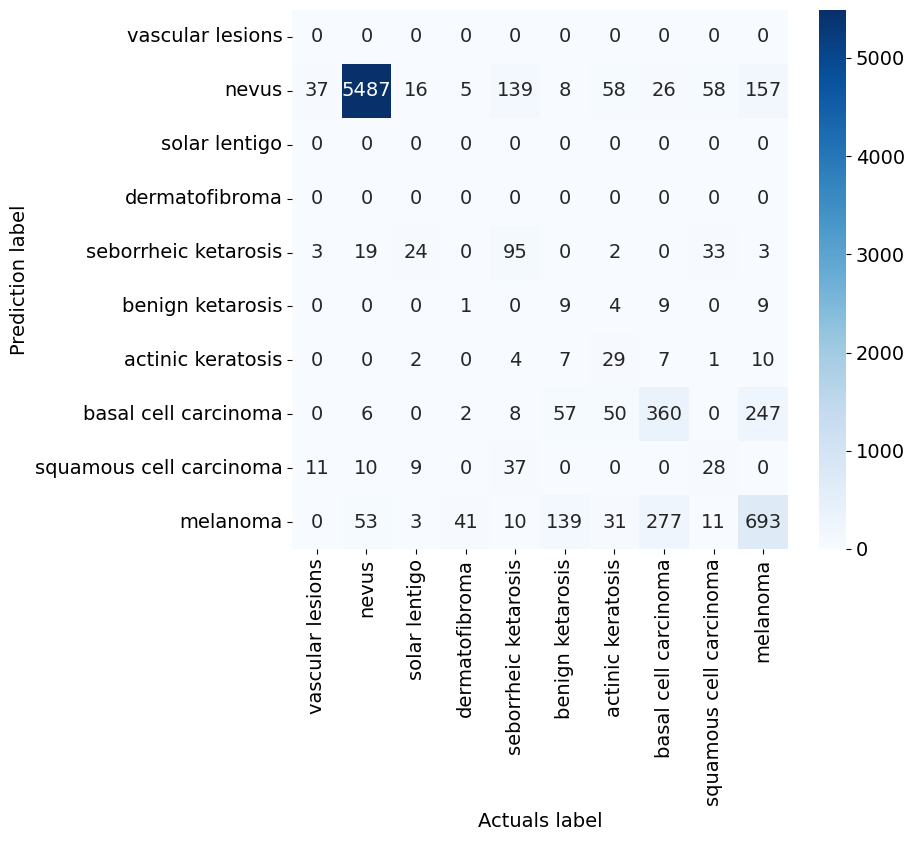

Sensitivity: 0.8030
Specificity: 0.9781
Precision: 0.8030
NPV: 0.9781
PPV: 0.8030
FNR: 0.1970
FPR: 0.0219
F1: 0.8030
Recall micro: 0.8030
Recall macro: 0.2879
Precision micro: 0.8030
Precision macro: 0.3550
F1 score micro: 0.8030
F1 score macro: 0.3013
Jaccard score micro: 0.6708
Jaccard score macro: 0.2229
Accuracy score: 0.8030
Matthews corrcoef: 0.6035
Specificity macro: 0.9666
Specificity micro: 0.9781
Specificity weighted: 0.8634
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8181
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9896
Specificity none - class benign ketarosis (5): 0.9972
Specificity none - class actinic keratosis (6): 0.9962
Specificity none - class basal cell carcinoma (7): 0.9517
Specificity none - class squamous cell carcinoma (8): 0.9918
Specificity none - class melanoma (9): 0.9218


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [45]:
actuals = []
predictions = []

test_NN(STUD_Model_4, testloader)

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

test_metric()

In [46]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_5 = MultimodalNN_light().to(device)

In [47]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.1, patience = 3)
optimizer = torch.optim.SGD(new_nn_light.parameters(), lr=0.001, momentum=0.9)

STUD_Model_5 = train_and_evaluate_kd (new_nn_light_5, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.75, 15)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:01:08
____________________________________________________________
Эпоха 1/15
   Тренировочная ошибка: 1.3929 Точность: 0.7343
        Время обучения: 00:01:10
   Валидационная ошибка: 0.9339 Точность: 0.7738
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7738
____________________________________________________________
Эпоха 2/15
   Тренировочная ошибка: 0.8947 Точность: 0.7791
        Время обучения: 00:01:10
   Валидационная ошибка: 0.7975 Точность: 0.7945
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7945
____________________________________________________________
Эпоха 3/15
   Тренировочная ошибка: 0.8120 Точность: 0.7881
        Время обучения: 00:01:10
   Валидационная ошибка: 0.7557 Точность: 0.7968
        Время тестирования: 00:00:10

Лучшая валидационная точность: 0.7968
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.474164



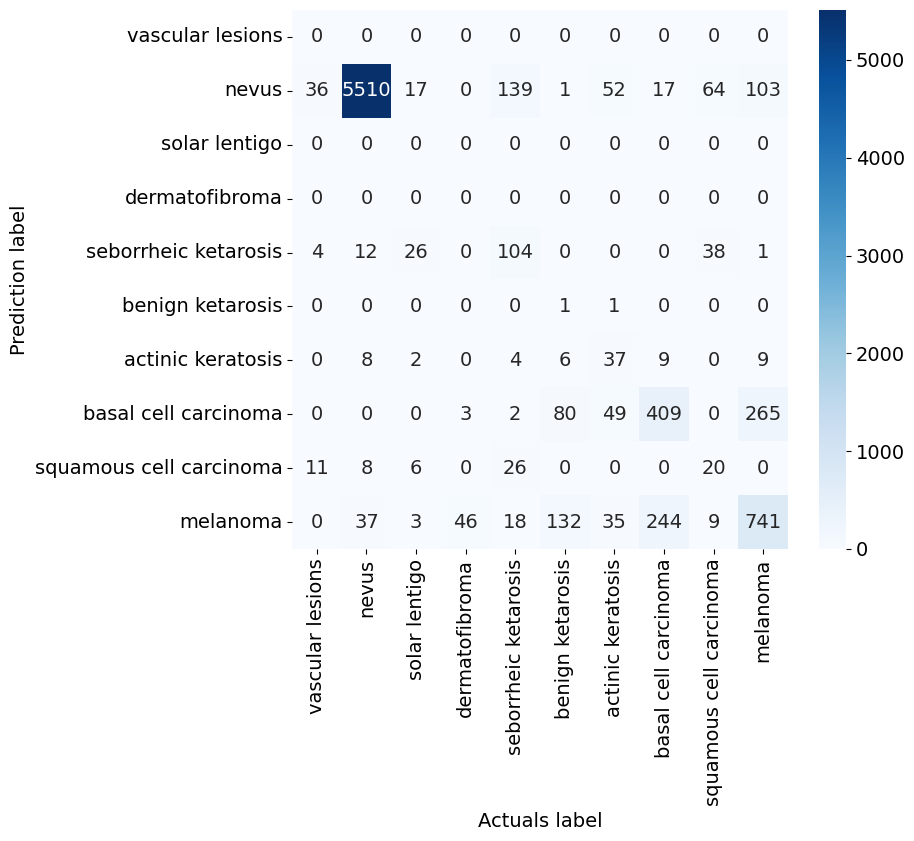

Sensitivity: 0.8175
Specificity: 0.9797
Precision: 0.8175
NPV: 0.9797
PPV: 0.8175
FNR: 0.1825
FPR: 0.0203
F1: 0.8175
Recall micro: 0.8175
Recall macro: 0.2978
Precision micro: 0.8175
Precision macro: 0.3857
F1 score micro: 0.8175
F1 score macro: 0.3068
Jaccard score micro: 0.6913
Jaccard score macro: 0.2315
Accuracy score: 0.8175
Matthews corrcoef: 0.6352
Specificity macro: 0.9700
Specificity micro: 0.9797
Specificity weighted: 0.8820
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8451
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9899
Specificity none - class benign ketarosis (5): 0.9999
Specificity none - class actinic keratosis (6): 0.9953
Specificity none - class basal cell carcinoma (7): 0.9480
Specificity none - class squamous cell carcinoma (8): 0.9938
Specificity none - class melanoma (9): 0.9275


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [49]:
actuals = []
predictions = []

test_NN(STUD_Model_5, testloader)

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

test_metric()

In [51]:
test_1 = test(NET_deep, testloader, device)
print(f"Точность модели-учителя: {test_1:.2f}%")

test_2 = test(NET_light, testloader, device)
print(f"Точность модели-ученика без учителя: {test_2:.2f}%")

test_3 = test(STUD_Model_1, testloader, device)
print(f"Точность модели-ученика со значениями Т=1, alpha=0.5: {test_3:.2f}%")

test_4 = test(STUD_Model_2, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.5: {test_4:.2f}%")

test_5 = test(STUD_Model_3, testloader, device)
print(f"Точность модели-ученика со значениями Т=5, alpha=0.5: {test_5:.2f}%")

test_6 = test(STUD_Model_4, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.25: {test_6:.2f}%")

test_7 = test(STUD_Model_5, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.75: {test_7:.2f}%")

____________________________________________________________
Время тестирования: 00:00:17
Время тестирования в секундах: 17.102106

Точность модели-учителя: 83.93%
____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.197364

Точность модели-ученика без учителя: 76.36%
____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.209814

Точность модели-ученика со значениями Т=1, alpha=0.5: 79.90%
____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.160140

Точность модели-ученика со значениями Т=2, alpha=0.5: 81.74%
____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.144297

Точность модели-ученика со значениями Т=5, alpha=0.5: 80.71%
____________________________________________________________
Время тестирования: 